In [94]:
from collections.abc import Callable, Iterable
from enum import Enum, auto, StrEnum
from pathlib import Path
# import traceback
from PIL import Image
import math
import sqlite3
import warnings
from typing import Callable


import torch
from torch import Tensor
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split, Subset

from torchvision import datasets, transforms
from torchvision.utils import make_grid

import cv2

import matplotlib.pyplot as plt

import numpy as np

import polars as pl

from tqdm import tqdm

In [68]:
batches = 8

In [69]:
class SinusoidalEmbedding(nn.Module):

    def __init__(self, dim: int, max_period = 10000):
        assert dim % 2 == 0, "dim must be divisible by 2"
        super().__init__()
        half = dim // 2
        freqs = torch.exp(-math.log(max_period) * torch.arange(half, dtype=torch.float32) / half)
        self.register_buffer('freqs', freqs, persistent=False)


    def forward(self, t: Tensor):
        t = t.reshape(-1).float()
        args = t[:, None] * self.freqs[None, :]
        return torch.concat([torch.sin(args), torch.cos(args)], dim=1)
    

def group_norm(channels: int, max_groups: int = 32):
    groups = max_groups
    while (channels % groups) != 0:
        groups //= 2
    return nn.GroupNorm(groups, channels)



class TimeEmbedding(nn.Module):

    def __init__(self,
                 base_dim: int,
                 emb_dim: int,
                 dropout: float = 0.1):
        
        super().__init__()
        self.sinusoid = SinusoidalEmbedding(dim=base_dim)
        self.mlp = nn.Sequential(
            nn.Linear(base_dim, emb_dim),
            nn.SiLU(),
            nn.Linear(emb_dim, emb_dim)
        )


    def forward(self, t: Tensor):

        return self.mlp(self.sinusoid(t))



class ResBlock(nn.Module):

    def __init__(self,
                 in_channel: int,
                 out_channel: int,
                 emb_dim: int,
                 dropout: float):
        super().__init__()

        self.norm1 = group_norm(in_channel)

        self.conv1 = nn.Conv2d(
            in_channels=in_channel,
            out_channels=out_channel,
            kernel_size=3,
            padding=1)

        self.time_proj = nn.Linear(emb_dim, out_channel)

        self.norm2 = group_norm(out_channel)

        self.dropout = nn.Dropout(dropout)
        
        self.conv2 = nn.Conv2d(
            in_channels=out_channel,
            out_channels=out_channel,
            kernel_size=3,
            padding=1)

        nn.init.zeros_(self.conv2.weight)
        nn.init.zeros_(self.conv2.bias)

        self.skip = (
            nn.Conv2d(
                in_channel, 
                out_channel, 
                kernel_size=1)
            
            if in_channel != out_channel 
            else 
            nn.Identity())




    def forward(self, x: Tensor, emb: Tensor):

        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.time_proj(F.silu(emb))[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.skip(x)




In [70]:
class UNet(nn.Module):

    def __init__(self, temb_dim: int = 512, dropout: float = 0.1):
        super().__init__()

        self.time_embed = TimeEmbedding(
            base_dim=128,
            emb_dim=temb_dim,
            dropout=dropout
        )

        rb = lambda input, output: ResBlock(
            in_channel=input,
            out_channel=output,
            emb_dim=temb_dim,
            dropout=dropout
        )


        # Encoder

        self.in_conv = nn.Conv2d(
            in_channels=3,
            out_channels=24,
            kernel_size=7,
            padding=3
        )


        self.enc01 = rb(24, 64)
        self.enc02 = rb(64, 128)

        # Downsampling

        self.downsamp01 = nn.Conv2d(
            in_channels=128, 
            out_channels=192, 
            kernel_size=3,
            stride=2,
            padding=1
        )

        self.enc03 = rb(192, 192)

        self.downsamp02 = nn.Conv2d(
            in_channels=192,
            out_channels=256,
            kernel_size=3,
            stride=2,
            padding=1
        )

        self.enc04 = rb(256, 256)

        self.downsamp03 = nn.Conv2d(
            in_channels=256,
            out_channels=384,
            kernel_size=3,
            stride=2,
            padding=1
        )

        self.enc05 = rb(384, 384)

        self.downsamp04 = nn.Conv2d(
            in_channels=384,
            out_channels=512,
            kernel_size=3,
            stride=2,
            padding=1
        )

        self.enc06 = rb(512, 512)


        # Bottleneck

        self.latent1 = rb(512, 512)
        self.latent2 = rb(512, 512)


        # Decoder

        self.upsamp01 = nn.ConvTranspose2d(
            in_channels=512, 
            out_channels=384,
            kernel_size=3,
            stride=2,
            padding=1,
            output_padding=1)

        self.dec01 = rb(384 + 384, 384)

        self.upsamp02 = nn.ConvTranspose2d(
            in_channels=384,
            out_channels=256,
            kernel_size=3,
            stride=2,
            padding=1,
            output_padding=1
        )

        self.dec02 = rb(256 + 256, 256)

        self.upsamp03 = nn.ConvTranspose2d(
            in_channels=256,
            out_channels=192,
            kernel_size=3,
            stride=2,
            padding=1,
            output_padding=1
        )

        self.dec03 = rb(192 + 192, 192)

        self.upsamp04 = nn.ConvTranspose2d(
            in_channels=192,
            out_channels=128,
            kernel_size=3,
            stride=2,
            padding=1,
            output_padding=1
        )

        self.dec04 = rb(128 + 128, 128)

        # Decoder

        self.dec05 = rb(128, 64)

        self.dec06 = rb(64, 24)

        self.out_norm = group_norm(24)

        self.out_conv = nn.Conv2d(
            in_channels=24,
            out_channels=3,
            kernel_size=3,
            stride=1,
            padding=1
        )

        nn.init.zeros_(self.out_conv.weight)
        nn.init.zeros_(self.out_conv.bias)

        return


    def forward(self, x: Tensor, t: Tensor):

        temb = self.time_embed(t)

        h = self.in_conv(x)             # 24 @ H
        h = self.enc01(h, temb)         # 64 @ H
        s1 = self.enc02(h, temb)        # 128 @ H

        s2 = self.enc03(self.downsamp01(s1), temb)          # 192 @ H/2
        s3 = self.enc04(self.downsamp02(s2), temb)          # 256 @ H/4
        s4 = self.enc05(self.downsamp03(s3), temb)          # 384 @ H/8
        h = self.enc06(self.downsamp04(s4), temb)           # 512 @ H/16

        h = self.latent1(h, temb)
        h = self.latent2(h, temb)

        h = self.dec01(                                     # 384 @ H/8
            torch.concat([self.upsamp01(h), s4], dim=1),
            temb
        )

        h = self.dec02(                                     # 256 @ H/4
            torch.concat([self.upsamp02(h), s3], dim=1),
            temb
        )

        h = self.dec03(                                     # 192 @ H/2
            torch.concat([self.upsamp03(h), s2], dim=1),
            temb 
        )


        h = self.dec04(                                     # 128 @ H
            torch.concat([self.upsamp04(h), s1], dim=1),
            temb 
        )


        h = self.dec05(h, temb)                             # 64 @ H

        h = self.dec06(h, temb)                             # 24 @ H


        return self.out_conv(F.silu(self.out_norm(h)))      # 3 @ H








Datasets Section

In [114]:
class Pneum(Dataset):

    def __init__(self):
        super().__init__()
        xray_dir = Path('datasets/nih-chest-xray/')
        data_path = xray_dir / 'BBox_List_2017.csv'
        df = pl.read_csv(data_path).filter(pl.col('Finding Label') == 'Pneumonia')
        self.df = df.select(['Bbox [x', 'y', 'w', 'h]'])
        item_names = set(df['Image Index'])
        items = sorted(xray_dir.glob('images_0*/images/*.png'))
        self.paths = [img for img in items if img.name in item_names]
        self.transform = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.ToTensor(),
            transforms.Normalize([0.5]*3, [0.5]*3)
        ])


    def __len__(self):
        return len(self.paths)


    def __getitem__(self, index):
        p = self.paths[index]
        image = Image.open(p).convert('RGB')
        return self.transform(image), 'Pneumonia'

In [71]:

class RESCLabel(StrEnum):
    NORMAL = 'NORMAL'
    DME = 'DME'
    AMD ='AMD'
    CNV = 'CNV'
    MH = 'MH'
    DRUSEN = 'DRUSEN'
    ALL = '*'

class SplitLabel(StrEnum):
    TEST = 'test'
    TRAIN = 'train'
    VAL = 'val'

class RESCDataset(Dataset):

    def __init__(self, 
                 root_dir: str | Path = 'datasets/retinal-oct', 
                 split:  SplitLabel= SplitLabel.TRAIN,
                 label: RESCLabel = RESCLabel.NORMAL, 
                 transform: Callable | None = None):

        label = '*' if label is None else label
        root_path = Path(root_dir)
        if root_path.is_dir():
            root_path = root_path / split
        if root_path.is_dir():
            self.paths = sorted(root_path.glob(f'{label}/*.jpg'))
            if not self.paths:
                raise FileNotFoundError(f'No dataset found in the directory {root_path.resolve() / label}')
        else:
            raise FileNotFoundError(f'{root_path.resolve()} not a directory') 
        classes = sorted({p.parent for p in self.paths})
        self.class_index = {v: i for i, v in enumerate(classes)}
        self.split = split
        self.transform = transform or transforms.Compose([
            transforms.Resize((128, 128)),
            transforms.ToTensor(),
            transforms.Normalize([0.5] * 3, [0.5] * 3)
        ])

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index: int):
        p = self.paths[index]
        image = Image.open(p).convert('RGB')
        return self.transform(image), self.class_index[p.parent]

In [72]:
class XRayLabel(StrEnum):
    NORMAL = 'NORMAL'
    PNEUMONIA = 'PNEUMONIA'

class ChestXRay(Dataset):

    def __init__(self,
                 root_dir: str | Path = 'datasets/chest_xray',
                 split: SplitLabel = SplitLabel.TRAIN,
                 label: XRayLabel = XRayLabel.NORMAL,
                 transform: Callable | None = None):
        super().__init__()
        root_path = Path(root_dir)
        if root_path.is_dir():
            root_path = root_path / split
        if root_path.is_dir():
            self.paths = sorted(root_path.glob(f'{label}/*.jpeg'))
            if not self.paths:
                raise FileNotFoundError(f'No dataset found in the directory {root_path.resolve() / label}')
        else:
            raise FileNotFoundError(f'{root_path.resolve()} is not a directory')
        classes = sorted((p.parent for p in self.paths))
        self.class_index = {v: i for i, v in enumerate(classes)}
        self.transform = transform or transforms.Compose([
            transforms.Resize((128, 128)),
            transforms.ToTensor(),
            transforms.Normalize([0.5] * 3, [0.5] * 3)
        ])

    def __len__(self):
        return len(self.paths)


    def __getitem__(self, index: int):
        p = self.paths[index]
        img = Image.open(p).convert('RGB')
        return self.transform(img), self.class_index[p.parent]

In [73]:
dat = RESCDataset(split='train', label=RESCLabel.NORMAL)
len(dat)

2300

In [74]:
xdat = ChestXRay()
print(len(xdat))


1238


In [75]:
def train(
        loader: DataLoader,
        epochs: int,
        beta_min: float,
        beta_max: float,
        checkpoint_dir: str,
        T: int = 1000,
        lr: float = 2e-4,
        device: str ='cuda',
        verbose: bool = True
):
    
    assert 0 <= beta_min < beta_max < 1,'beta_min must be less than beta_max, and their range is [0, 1)'
    # assert 0 <= noise <= 1, 'the value of noise has a range of [0, 1]' 

    if device == 'cuda' and  torch.cuda.is_available() == False:
        warnings.warn('GPU is notavailable, use device="cpu"', RuntimeWarning)

    betas = torch.linspace(
        beta_min,
        beta_max,
        T,
        device=device
    )

    alpha_bar = torch.cumprod(1-betas, dim=0)

    model = UNet()
    model.to(device)

    checkpoint = Path(checkpoint_dir)

    if checkpoint.exists():

        try:
            state_dict = torch.load(
                f=checkpoint,
                map_location=device,
                weights_only=True
            )

            model.load_state_dict(state_dict=state_dict)

            print(f'The checkpoint named {checkpoint_dir} as been loaded')

        except RuntimeError as e:

            e.add_note(f'[Checkpoint failure] while loading {checkpoint}')
            raise

        except Exception as e:
            exc = type(e)
            raise exc('[Checkpoint failure] ' % e) from e

    else:
        if verbose:
            print(f'No checkpoint named {checkpoint_dir} was found')
            print(f'A new checkpoint will be created')

    optimizer = optim.Adam(
        params=model.parameters(),
        lr=lr
    )

    scaler = torch.amp.GradScaler('cuda')

    model.train()

    loader_size = len(loader)

    for epoch in tqdm(range(epochs), desc=f'Training {epochs} epochs'):

        running_loss = 0.0

        for x0, _ in loader:

            x0 = x0.to(device)
            # batch of current dataset
            batch = x0.shape[0]
            # random timestep
            ts = torch.randint(
                low=0,
                high=T,
                size=(batch,),
                device=device
            )
            # shape -> [b]
            alpha_bar_t: Tensor = alpha_bar[ts]
            # shape -> [b, 1, 1, 1]
            alpha_bar_t = alpha_bar_t[:, None, None, None]
            # noise
            epsilon: Tensor = torch.randn_like(x0)
            # noisy data
            xt: Tensor = (alpha_bar_t.sqrt() * x0) + ((1 - alpha_bar_t).sqrt() * epsilon)

            with torch.autocast('cuda', dtype=torch.float16):
                # predicted noise
                epsilon_pred = model(xt, ts)

            loss = F.mse_loss(epsilon_pred, epsilon)

            optimizer.zero_grad()                   # clears old grads
            scaler.scale(loss).backward()           # computes new grads
            scaler.unscale_(optimizer=optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer=optimizer)        # update weights
            scaler.update()                         # adjusts the scale
        
            # loss.backward()
            # nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            # optimizer.step()

            running_loss += loss.item()

        average_loss = running_loss / loader_size

        print(
            f'Epoch {epoch + 1}, / {epochs}',
            f'Loss: {average_loss:.6f}'
        )

        torch.save(model.state_dict(), checkpoint)

    return model





    
    



In [76]:
data = RESCDataset(split='train', label=RESCLabel.NORMAL)
dataloader = DataLoader(
    dataset=data,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    drop_last=False,
    multiprocessing_context='fork'
)

beta_min=1e-4
beta_max=0.02
T=10000,

# model = train(loader=dataloader, epochs=20, beta_min=beta_min, beta_max=beta_max, checkpoint_dir='checkpoints/resc.pth')

In [77]:
data02 = ChestXRay()

dataloader = DataLoader(
    dataset=data02,
    batch_size=8,
    shuffle=True,
    num_workers=2,
    drop_last=False,
    multiprocessing_context='fork'
)

model = train(loader=dataloader, epochs=5, beta_min=beta_min, beta_max=beta_max, checkpoint_dir='checkpoints/xray.pth')

The checkpoint named checkpoints/xray.pth as been loaded


Training 5 epochs:   0%|          | 0/5 [00:00<?, ?it/s]

Epoch 1, / 5 Loss: 0.006069


Training 5 epochs:  20%|██        | 1/5 [00:58<03:55, 58.96s/it]

Epoch 2, / 5 Loss: 0.007185


Training 5 epochs:  40%|████      | 2/5 [01:58<02:57, 59.20s/it]

... (2 outputs left out)

Epoch 4, / 5 Loss: 0.005595


Training 5 epochs:  80%|████████  | 4/5 [03:57<00:59, 59.56s/it]

Epoch 5, / 5 Loss: 0.006077


Training 5 epochs: 100%|██████████| 5/5 [04:57<00:00, 59.54s/it]


The contional mean, expectation or the center of the probability distribution
$$\mathbb{E}[x_{t-1} \mid x_t] = \int x_{t-1}\, p(x_{t-1} \mid x_t)\, dx_{t-1}$$
mean → $\mu_\theta(x_t, t)$
$$\mu_\theta(x_t, t) = \frac{1}{\sqrt{\alpha_t}} \left( x_t - \frac{\beta_t}{\sqrt{1 - \bar\alpha_t}}\, \epsilon_\theta(x_t, t) \right)$$

In [78]:
@torch.no_grad()
def sample_(
        xt: Tensor,
        model: nn.Module,
        t_start: int = 999,
        T: int = 1000,
        beta_min: float = 1e-4,
        beta_max: float = 0.02,
        snapshot_every: int = 0,
        device: str = 'cuda'
):
    
    assert isinstance(xt, Tensor), 'xt must be an instance of torch.Tensor'
    assert isinstance(model, nn.Module), 'model must be an instance of torch.nn.Module'
    assert 0 <= t_start < T, 't_start cannot be greater than T'
    assert snapshot_every >= 0, 'snapshot_every cannot be a negative integer'

    device = torch.device(device)
    xt = xt.to(device)

    was_training = model.training
    
    model.eval()                  # disable dropout

    snapshots = []

    betas = torch.linspace(
        start=beta_min,
        end=beta_max,
        steps=T,
        device=device
    )

 
    alphas = 1 - betas
    alpha_bar = torch.cumprod(input=alphas, dim=0)

    denorm: Callable[[Tensor], Tensor] = lambda x: (x.clamp(-1, 1) + 1) / 2           # denormalization

    try:

        for t in tqdm(range(t_start, -1, -1), desc='sampling', total=(t_start + 1)):

            # batch = xt.shape[0]
            ts = torch.full((xt.shape[0],), t, device=device, dtype=torch.long)

            with torch.autocast(device_type=device.type, dtype=torch.float16, 
                                enabled=(device.type == 'cuda')):

                epsilon = model(xt, ts)

            epsilon = epsilon.float()

            mean = (xt - betas[t]/(1 - alpha_bar[t]).sqrt() * epsilon) / alphas[t].sqrt()

            if t > 0:
                xt = mean + betas[t].sqrt() * torch.randn_like(xt)
            else:
                xt = mean

            if bool(snapshot_every) and (t % snapshot_every) == 0:
                snapshots.append(denorm(xt))

    finally:

        model.train(was_training)

    # return (xt.clamp(-1, 1) + 1) / 2 
    out = denorm(xt)
    return (out, snapshots)
        

In [79]:
# sample

@torch.no_grad()
def sample(
    model: nn.Module,
    batch: int = 8,
    T: int = 1000,
    beta_min: float = 1e-4,
    beta_max: float = 0.02,
    size: tuple[int, int] = (128, 128),
    device: str = 'cuda'
):
    model.eval()            # disable droput

    betas = torch.linspace(
        start=beta_min,
        end=beta_max,
        steps=T,
        device=device
    )

    alphas = 1 - betas
    alpha_bar = torch.cumprod(input=alphas, dim=0)   

    x0 = torch.randn(batch, 3, *size, device=device)     # pure noise

    for t in tqdm(reversed(range(T)), desc='sampling', total=T):

        ts = torch.full((batch,), t, device=device, dtype=torch.long)

        with torch.autocast(device_type=device, dtype=torch.float16):
            epsilon = model(x0, ts)

        epsilon = epsilon.float()

        mean = (x0 - betas[t]/(1 - alpha_bar[t]).sqrt() * epsilon) / alphas[t].sqrt()

        if t > 0:
            x0 = mean + betas[t].sqrt() * torch.randn_like(x0)
        else:
            x0 = mean

    model.train()

    return (x0.clamp(-1, 1) + 1) / 2

        

Ground Truth


torch.Size([8, 256, 256, 3])

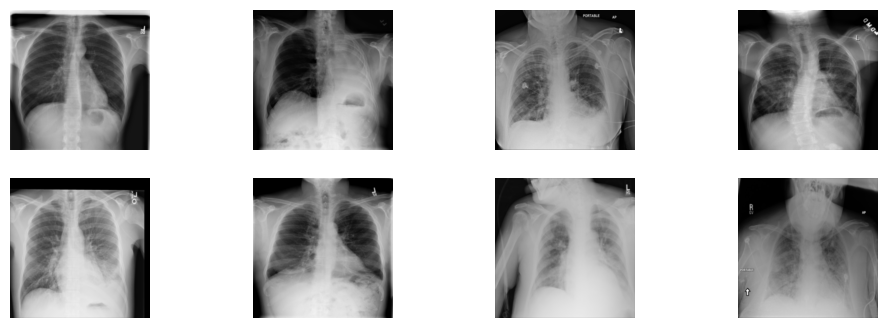

In [115]:
# samp = ChestXRay()

samp = Pneum()


sample_loader = DataLoader(dataset=samp, batch_size=batches, shuffle=True)

images, labels = next(iter(sample_loader))

images = (images + 1) / 2 

images = torch.clamp(images, 0.0, 1.0) 

images = images.permute(0, 2, 3, 1).cpu()


fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(12, 4))

axes = axes.flatten()

for i, ax in enumerate(axes):
    ax.imshow(images[i])
    ax.axis('off')





images.shape


Generated Sample

sampling: 100%|██████████| 1000/1000 [02:10<00:00,  7.68it/s]


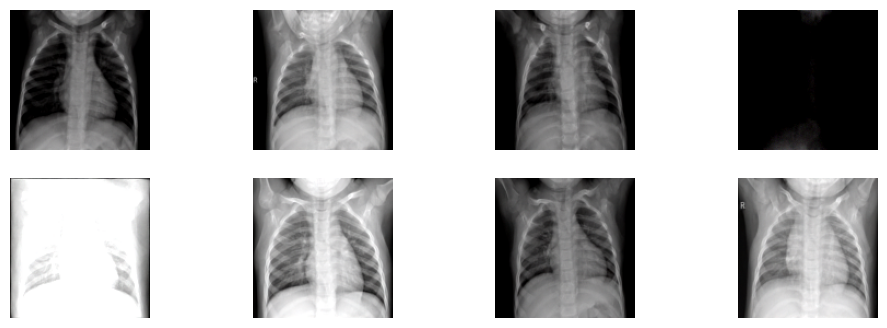

In [81]:
torch.manual_seed(0)

img0 = sample(model, batch=8)

img = img0.permute(0, 2, 3, 1).cpu()

# grid = make_grid(img, nrow=4, padding=2)

fig, axes = plt.subplots(nrows=2, ncols=4, figsize=(12, 4))

axes = axes.flatten()

for i, ax in enumerate(axes):
    ax.imshow(img[i])
    ax.axis('off')

# plt.figure(figsize=(10, 5))

# small = F.interpolate(img, size=(64, 64), mode='area')   # [B, 3, 64, 64]
# plt.imshow(make_grid(small, nrow=4).permute(1, 2, 0).cpu())

# # plt.imshow(grid.permute(1, 2, 0).cpu( ))

# plt.axis('off')

# plt.show()





Images at different time-scales

sampling: 100%|██████████| 1000/1000 [01:07<00:00, 14.81it/s]


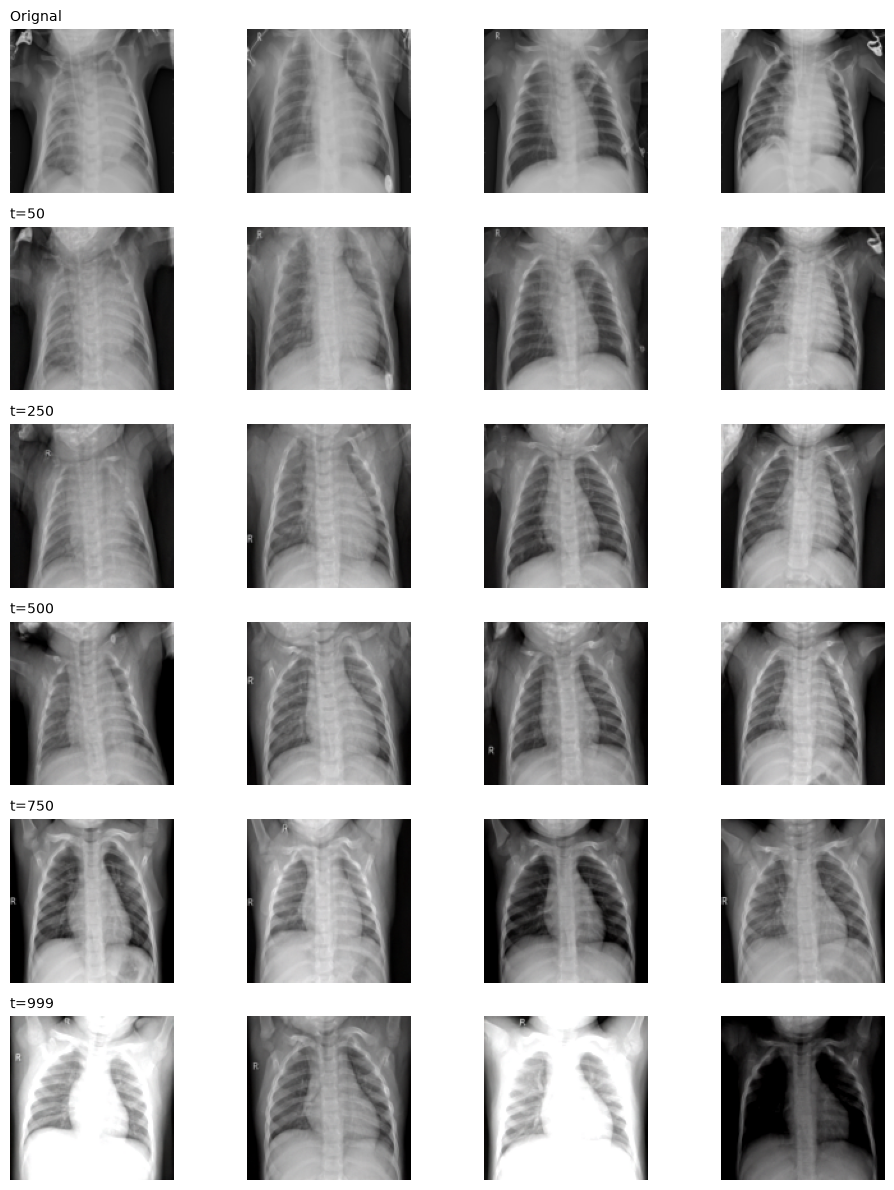

In [82]:
xray_data = ChestXRay(split=SplitLabel.TEST, label=XRayLabel.PNEUMONIA)


dataset_loader = DataLoader(dataset=xray_data, batch_size=4, shuffle=True)

x0, labels = next(iter(dataset_loader))

device = torch.device('cuda')

x0 = x0.to(device)

betas = torch.linspace(start=1e-4, end=0.02, steps=1000, device=device)
alpha_bar = torch.cumprod(1-betas, dim=0)

timesteps = [50, 250, 500, 750, 999]


rows = [(x0.clamp(-1,1) + 1) / 2]
titles = ['Orignal'] + [f't={item}' for item in timesteps]

for t in timesteps:       # time-scales

    noise = torch.randn_like(x0)
    xt = (alpha_bar[t].sqrt() * x0) + ((1 - alpha_bar[t]).sqrt() * noise)
    out, _ = sample_(xt, model=model, t_start=t)
    rows.append(out)


# x = out.permute(0, 2, 3, 1).cpu()

fig, axes = plt.subplots(nrows=len(rows), ncols=out.shape[0], figsize=(10, 12))

for r, (images, title) in enumerate(zip(rows, titles)):

    images = images.permute(0, 2, 3, 1).cpu()

    for c in range(images.shape[0]):

        axes[r, c].imshow(images[c].squeeze(-1), cmap='gray')
        axes[r, c].axis('off')

    axes[r, 0].set_title(title, loc='left', fontsize=10)


plt.tight_layout()
plt.show()



Abnormal sample

In [83]:
len([(x0.clamp(-1,1) + 1) / 2])

1

In [84]:
@torch.no_grad()
def abnormal_test(model, data_loader, t=500):

    model.eval()

    x0, labels = next(iter(data_loader))

    device = torch.device('cuda')

    x0 = x0.to(device)

    betas = torch.linspace(
        start=1e-4,
        end=0.02,
        steps=1000,
        device=device
    )

    alpha_bar = torch.cumprod(1 - betas, dim=0)

    titles = ['Original Pneumonia Sample'] + [f't={ts}' for ts in range(t, -1, -(t//4))]
    # titles.append('final')

    rows = [(x0.clamp(-1, 1) + 1) / 2]  #  first row has the original pneumonia samples

    epsilon = torch.randn_like(x0)

    xt = (alpha_bar[t].sqrt() * x0) + (1 - alpha_bar[t]).sqrt() * epsilon

    rows.append((xt.clamp(-1, 1) + 1) / 2)  #  second row has the noisy sample before reconstruction 

    out, snapshots = sample_(
        xt=xt,
        model=model,
        t_start=t,
        snapshot_every=t//4
    )

    # rows.append(xt)


    rows.extend(snapshots[1: -1])

    titles.append('t=0')

    rows.append(out)


    fig, axes = plt.subplots(
        nrows=len(rows), 
        ncols=out.shape[0],
        figsize=(10, 12)
        )

    for r, (images, title) in enumerate(zip(rows, titles)):

        images = images.permute(0, 2, 3, 1).cpu()

        for c in range(out.shape[0]):

            axes[r, c].imshow(images[c].squeeze(-1), cmap='gray')
            axes[r, c].axis('off')

        axes[r, 0].set_title(title, loc='left', fontsize=10)

    plt.tight_layout()
    plt.show()


sampling: 100%|██████████| 251/251 [00:16<00:00, 14.89it/s]


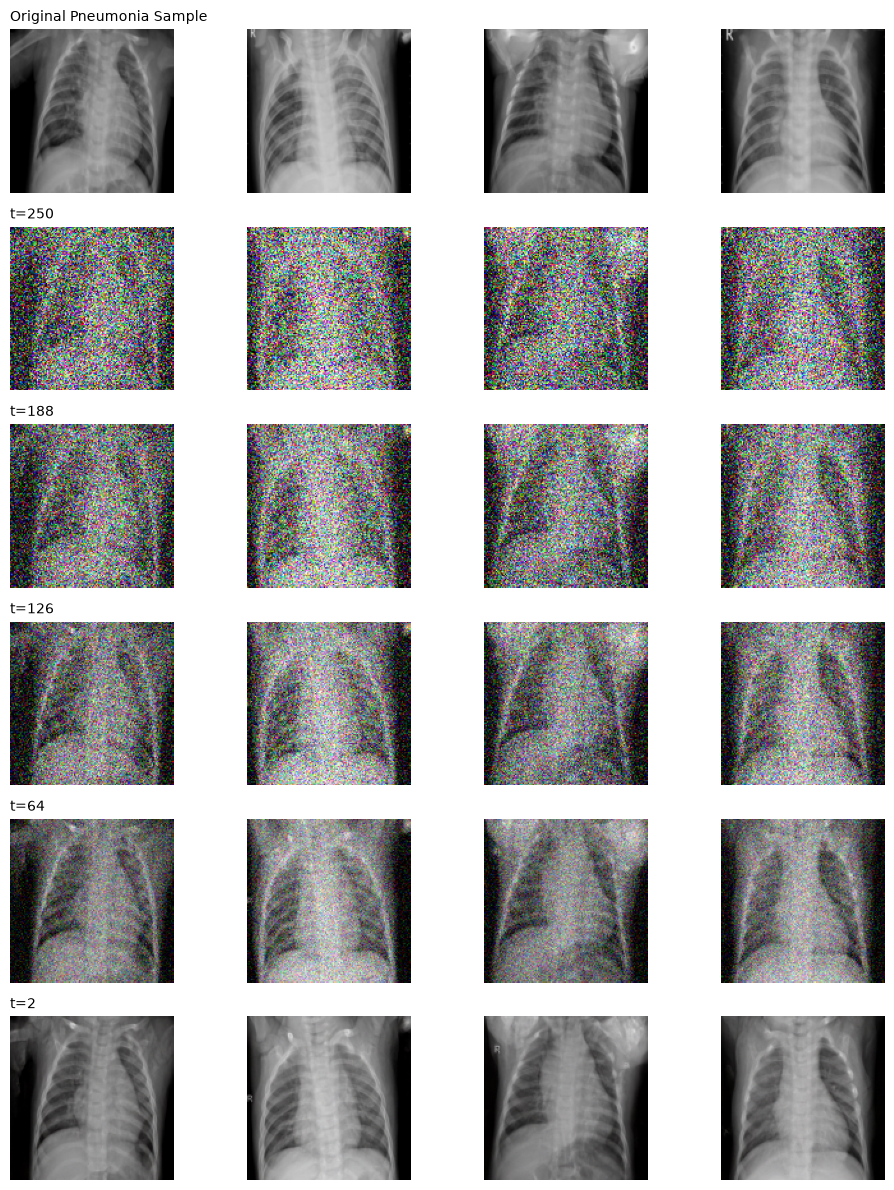

In [85]:
abnorm_data = ChestXRay(
        split=SplitLabel.TEST, 
        label=XRayLabel.PNEUMONIA)

abnorm_loader = DataLoader(
        dataset=abnorm_data,
        batch_size=4,
        shuffle=True)

abnormal_test(model, abnorm_loader, t=250)

In [86]:
@torch.no_grad()
def reconstruct(
    input: Tensor,
    model: nn.Module,
    time_start: int,
    beta_min: float = 1e-4,
    beta_max: float = 0.02,
    T: int = 1000,
    snapshots_seq: Iterable[int] = None,
    device_type: str = 'cuda'
):
    assert 0 <= time_start < T, 't_start must be an integer in the range 0 <= t_start < T'
    assert isinstance(model, nn.Module), 'model must be an instance of torch.nn.Module'

    was_training = model.training
    model.eval()                    # disable dropouts

    denorm: Callable[[Tensor], Tensor] = lambda x: (x.clamp(-1, 1) + 1) / 2

    device = torch.device(device_type)
    
    x0 = input.to(device)

    betas = torch.linspace(
        start=beta_min,
        end=beta_max,
        steps=T,
        device=device
    )

    alpha_bar = torch.cumprod(1 - betas, dim=0)

    noise = torch.randn_like(x0)              # noise

    xt = (alpha_bar[time_start].sqrt() * x0) + ((1 - alpha_bar[time_start]).sqrt() * noise)   # add noise to sample

    snapshots = [denorm(x0), denorm(xt)]

    members = {k for k in (snapshots_seq or []) if 0 < k < time_start}

    # make each entry unique and the sequence in descending order

    seq = sorted(members, reverse=True)       
      
    titles = ['original', f't = {time_start}'] + [f't = {k}' for k in seq]

    try:

        for t in tqdm(range(time_start, -1, -1), desc='reconstructing', total=(time_start + 1)):
            
            ts = torch.full((xt.shape[0],), t, device=device, dtype=torch.long)

            with torch.autocast(
                device_type=device.type, 
                dtype=torch.float16,
                enabled=(device.type == 'cuda')
                ):

                epsilon = model(xt, ts)

            if t in members:

                snapshots.append(denorm(xt))

            epsilon = epsilon.float()

            mean = (xt - (betas[t] * epsilon / (1 - alpha_bar[t]).sqrt())) / (1 - betas[t]).sqrt()

            if t > 0:
            
                xt = mean + betas[t].sqrt() * torch.randn_like(xt)

            else:
            
                xt = mean
        
        snapshots.append(denorm(xt))

        titles.append('t = 0')

    finally:

        model.train(was_training)

    
    return denorm(xt), snapshots, titles 





In [87]:
def display_stages(
        x0: Tensor, 
        model: nn.Module,
        time_start: int,
        seq: Iterable[int],
        device_type: str = 'cuda'
        ):

    xt, snapshots, titles = reconstruct(
        input=x0,
        model=model,
        time_start=time_start,
        snapshots_seq=seq,
        device_type=device_type
    )

    fig, axes = plt.subplots(
        nrows=len(snapshots),
        ncols=xt.shape[0],
        figsize=(10, 2*len(snapshots))
    )

    for r, (img, title) in enumerate(zip(snapshots, titles)):

        img = img.permute(0, 2, 3, 1).cpu()

        for c in range(img.shape[0]):

            axes[r, c].imshow(img[c].squeeze(-1), cmap='gray')
            axes[r, c].axis('off')

        axes[r, 0].set_title(title, fontsize=10, loc='left')

    plt.tight_layout()
    plt.show()

    

reconstructing: 100%|██████████| 301/301 [00:18<00:00, 15.99it/s]


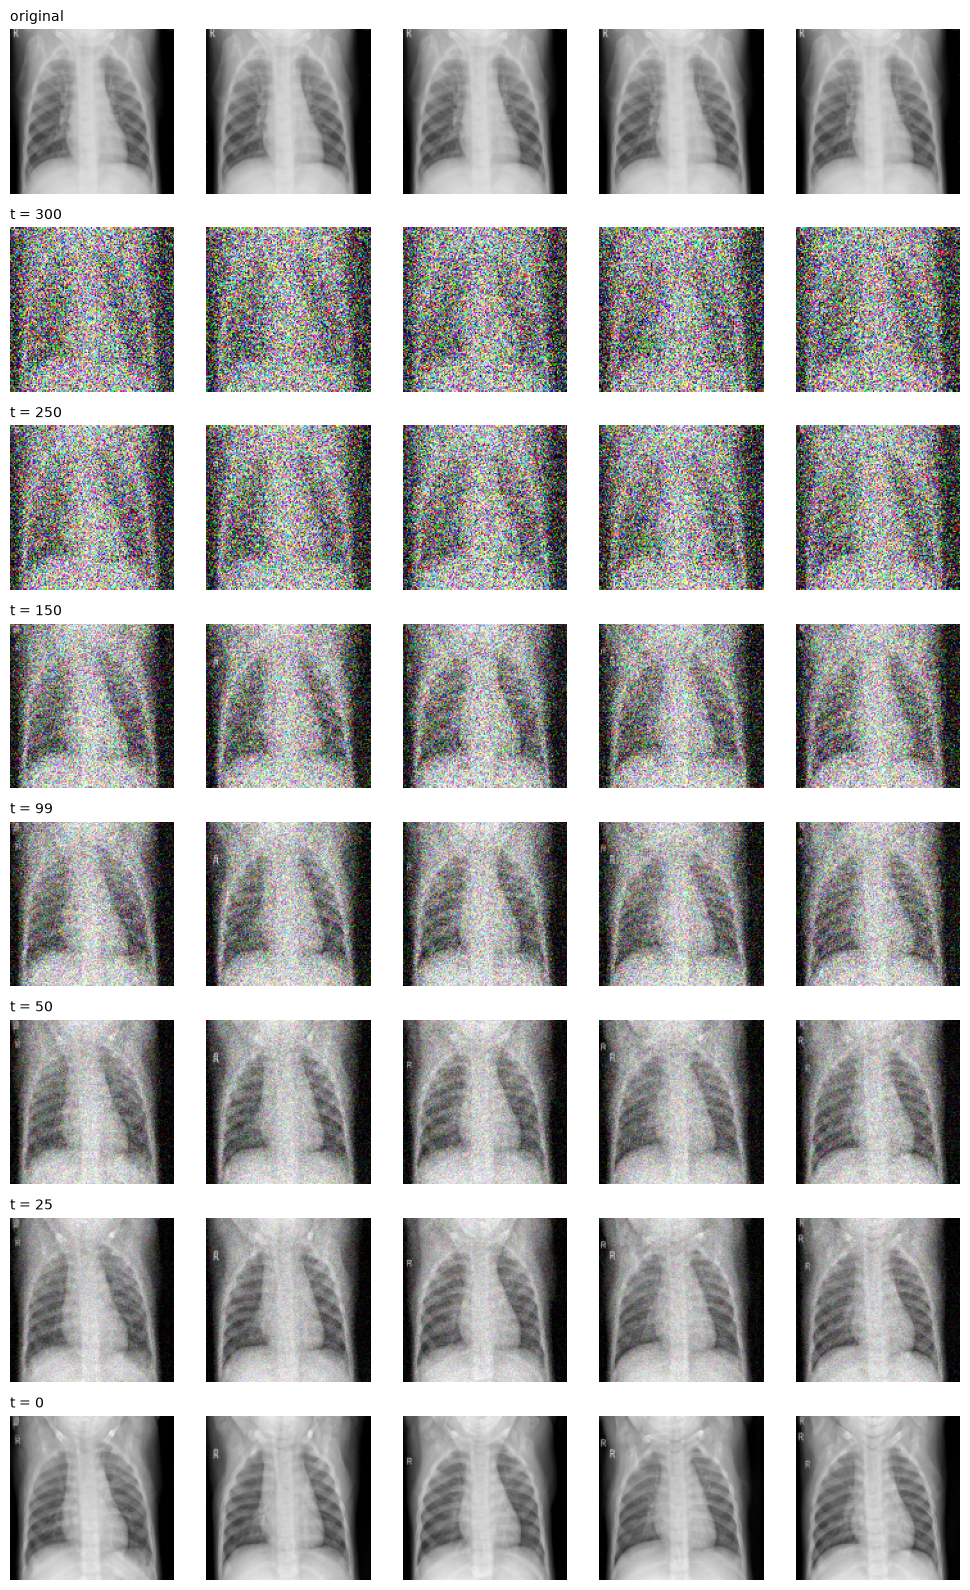

In [118]:
pneumonia_data = ChestXRay(
        split=SplitLabel.TEST, 
        label=XRayLabel.PNEUMONIA)

# pneumonia_data = Pneum()

index = torch.randint(low=0, high=len(pneumonia_data), size=(1,)).item()

batch_size = 5

# abnorm_loader = DataLoader(
#         dataset=abnorm_data,
#         batch_size=4,
#         shuffle=True)

subset = Subset(pneumonia_data, [index] *  batch_size)

loader = DataLoader(
    dataset=subset,
    batch_size=batch_size,
    shuffle=False)

x0, _ = next(iter(loader))


xt, snapshots, titles = reconstruct(
    input=x0,
    model=model,
    time_start=300,
    snapshots_seq=[250, 150, 99, 50, 25]
)


fig, axes = plt.subplots(ncols=xt.shape[0], nrows=len(titles), figsize=(10, 2 * len(titles)))

for r, (img, title) in enumerate(zip(snapshots, titles)):

    img = img.permute(0, 2, 3, 1).cpu()     #   B C H W  -->  B H W C

    for c in range(xt.shape[0]):

        axes[r, c].imshow(img[c].squeeze(-1), cmap='gray')
        axes[r, c].axis('off')

    axes[r, 0].set_title(title, loc='left', fontsize=10)


plt.tight_layout()
plt.show()

reconstructing: 100%|██████████| 151/151 [00:12<00:00, 11.89it/s]


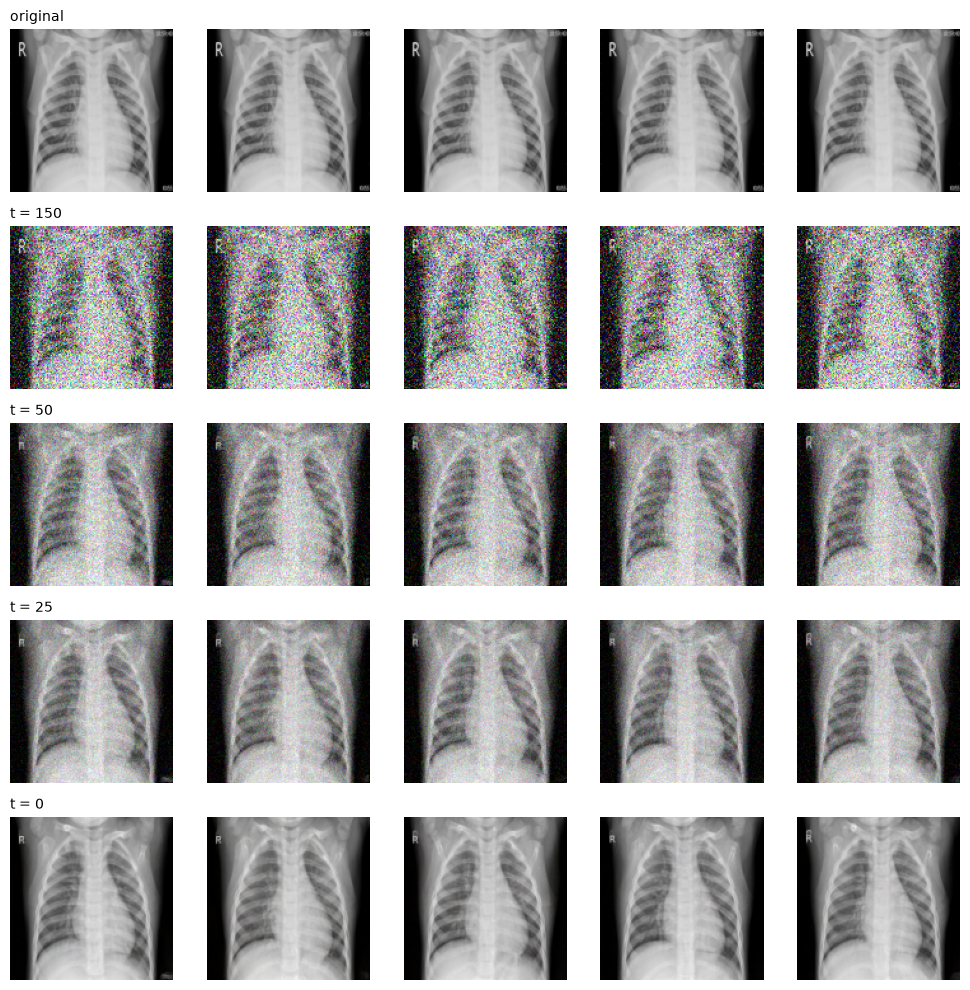

In [89]:
x0, _ = next(iter(loader))

display_stages(x0, model, 150, [200, 150, 50, 25])

In [90]:
class MorphologicalOpening(nn.Module):

    def __init__(self, kernel_size=3):
        assert (kernel_size > 0) and (kernel_size % 2), 'Kernel size must be an odd number'
        super().__init__()

        self.pool = nn.MaxPool2d(
            kernel_size=kernel_size,
            stride=1,
            padding=kernel_size//2)

    def forward(self, x):
        # x -->  [B, 1, H, W] 

        x = x.float()

        # erosion
        x = 1 - self.pool(1 - x)

        # dilation
        x = self.pool(x)

        return x

In [91]:
3 % 2 and 3 > 0

True

In [92]:
class BoundingBox(nn.Module):

    def __init__(self):

        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MacPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten()
        )

        self.box = nn.Sequential(
            nn.Linear(64, 4),
            nn.Sigmoid()
        )

    def forward(self, x):

        x = self.features(x)

        return self.box(x)

Medoid
$$m = \arg\min_{i} \sum_{j=1}^{n} d(x_i, x_j)$$

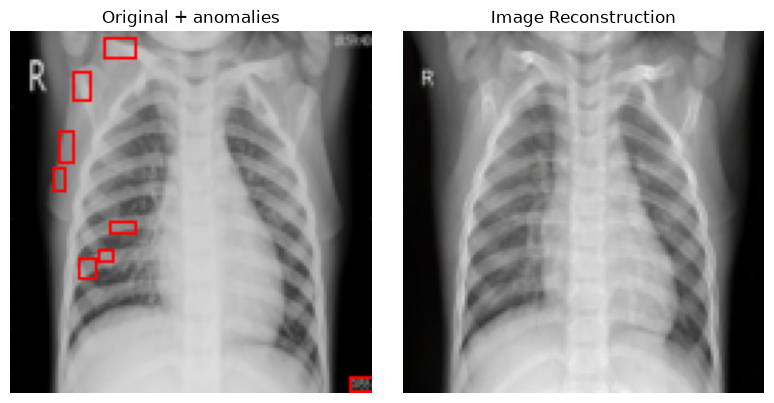

In [104]:
# [B C H W]

xx = (x0.clamp(-1, 1) + 1) / 2

xx = xx.to(xt.device)

diff = (xx - xt).mean([1])

morph = MorphologicalOpening(kernel_size=3)

diff = morph(diff) 

mask = diff > torch.quantile(diff.flatten(), 0.95)

vote = mask.float().mean(dim=0)  # shape [H W]

total = (vote >= 0.5).to(torch.uint8).cpu().numpy()

n, labels, stats, centroids = cv2.connectedComponentsWithStats(total, connectivity=8)


# median = xt.median(dim=0).values
mean = xt.mean(0, keepdim=True)
idx = ((xt - mean)**2).flatten(1).mean(1).argmin()
recon = xt[idx]

recon = recon.permute(1, 2, 0).flip([-1])

base = (recon * 255).to(torch.uint8).contiguous().cpu().numpy()


orig = (xx[0].permute(1, 2, 0).flip([-1]) * 255).to(torch.uint8).contiguous().cpu().numpy()


for i in range(1, n):

    x, y, w, h, area = stats[i]
    
    if area < 15:
        continue 

    cv2.rectangle(orig, (x, y), (x+w, y+h), color=(0, 0, 255), thickness=1)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(8, 4))

axes[0].imshow(cv2.cvtColor(orig, cv2.COLOR_BGR2RGB))
axes[0].set_title('Original + anomalies') 
axes[1].imshow(cv2.cvtColor(base, cv2.COLOR_BGR2RGB))
axes[1].set_title('Image Reconstruction')

for i in range(2):
    axes[i].axis('off')

plt.tight_layout()
plt.show()





In [ ]:
# x0, _ = next(iter(loader))

# xt, snapshots, titles = reconstruct(x0, model, 400, snapshots_seq=[350, 250, 150, 50, 25])

diff = (x0.cpu() - xt.cpu()).abs().mean(dim=0)

diff = diff.permute(1, 2, 0)  # [C H W] --> [H W C]

diff = diff.flip(dims=[-1])     # convert the channel from RGB to BG

In [ ]:
# threshold = torch.quantile(input=diff.flatten(), q=0.95)
# mask = diff > threshold
# mask = mask.to(torch.uint8)


In [ ]:
torch.randint(0, 20, (1,)).item()

[3] * 4

y = list(range(7))

y[-1], 

(6,)


$\boxed{O=\left\lfloor\frac{I+2P-K}{S}\right\rfloor+1}$


- \(I\): input size (height or width)
- \(O\): output size
- \(P\): padding on each side
- \(K\): kernel size
- \(S\): stride

In [ ]:
    # padding
    # valid = 0
    # same = 1

def conv_size(input: int, k:int, pad: int = 0, s:int=1):
    """
    input = in-channel
    k = kernel
    s = stride
    pad = padding
    """
    assert  k % 2, 'an odd number is preferred'

    return ((input + (2 * pad) - k) // s) + 1


def transpose_size(input, k, pad, s = 1, out=0, d=1):
    """
    input = in-channel
    k = kernel
    s = strise
    pad = padding
    oot = out-padding
    d =dilation
    """
    assert  k % 2, 'an odd number is preferred'

    return (input - 1) * s - (2 * pad) - (d * (k - 1)) + out + 1

In [ ]:
conv_size(input=1024, k=3 ,pad=1, s=2)


512

In [ ]:
set([])

set()